# COM-490 Final — Validation Notebook

Each section justifies one modelling decision used by the journey planner
in `backend.py`:

1. **Conditioning key** — feature importance picks the grouping columns
   for `StopDelayLookup`.
2. **Parametric family** — held-out AIC selects Gumbel over the
   alternatives (Normal, Skew-Normal, shifted Gamma, ...).
3. **MC sample size** — variance bound justifies `n_samples = 10 000`
   for transfer-probability estimation.
4. **Train/test split** — disjoint operating-day partitions used by all
   downstream evaluations.
5. **Lookup-table accuracy** — per-bin CDF MAE for the discrete-PMF and
   Gumbel-parameter tables on held-out days.
6. **ML-parametrised Gumbel** — regression models that output continuous
   `(μ, β)` per row, compared against the lookup baseline.
7. **Point-prediction MAE** — single-trip error of every strategy
   considered.

## Setup — environment, Spark, Trino

In [1]:
import os, sys, pwd, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

username = pwd.getpwuid(os.getuid()).pw_name
hadoopFS = os.getenv('HADOOP_FS', None)

# Your existing Trino auth (used by JourneyPlanner):
#   - EPFL_COM490_TOKEN     (JWT)
#   - TRINO_URL             (scheme://host:port)
assert os.getenv('EPFL_COM490_TOKEN'), 'Missing EPFL_COM490_TOKEN env var'
assert os.getenv('TRINO_URL'),         'Missing TRINO_URL env var'
assert hadoopFS,                       'Missing HADOOP_FS env var'

# Set these to the right values for your group:
USER_NS     = f'iceberg.{username}_iceberg'         # your personal namespace, e.g. iceberg.alice
GROUP_NAME  = 'D2'                          # change me
REGION_UUIDS = [ 
    'a7a21b73-6ffe-4fbf-a635-6e2b961f3072', # 'uuid-of-lausanne-region',
    'e168fd57-f57a-4075-a350-0dcfbb55147f', # 'uuid-of-oeust-lausanne-region',
]
ISTDATEN_PARQUET = f'{hadoopFS}/user/{username}/assignment2/lausanne_clean.parquet'
FINAL_DIR        = f'{hadoopFS}/user/{username}/final'

# Output parquet paths for the delay-distribution build:
P_STOP_DELAYS         = f'{FINAL_DIR}/stop_delays.parquet'
P_STOP_DELAYS_NOLINE  = f'{FINAL_DIR}/stop_delays_no_line.parquet'
P_STOP_DELAYS_NODOW   = f'{FINAL_DIR}/stop_delays_no_dow.parquet'
P_SEGMENT_TT          = f'{FINAL_DIR}/segment_tt.parquet'
P_SEGMENT_TT_NOLINE   = f'{FINAL_DIR}/segment_tt_no_line.parquet'
P_BUS_SNAPSHOT        = f'{FINAL_DIR}/bus_state_snapshot.parquet'
P_TRIP_TO_LINE        = f'{FINAL_DIR}/trip_to_line.parquet'

print(f'username   = {username}')
print(f'hadoopFS   = {hadoopFS}')
print(f'USER_NS    = {USER_NS}')
print(f'FINAL_DIR  = {FINAL_DIR}')


username   = chaurasi
hadoopFS   = hdfs://iccluster061.iccluster.epfl.ch:9000
USER_NS    = iceberg.chaurasi_iceberg
FINAL_DIR  = hdfs://iccluster061.iccluster.epfl.ch:9000/user/chaurasi/final


In [2]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from random import randrange

spark = (SparkSession.builder
    .appName(username + '-final')
    .config('spark.ui.port', randrange(4050, 4450, 5))
    .config('spark.executorEnv.PYTHONPATH', ':'.join(sys.path))
    .config('spark.jars',
            f'{hadoopFS}/data/com-490/jars/iceberg-spark-runtime-3.5_2.13-1.6.1.jar,'
            f'{hadoopFS}/data/com-490/jars/sedona-spark-shaded-3.5_2.13-1.7.1.jar,'
            f'{hadoopFS}/data/com-490/jars/geotools-wrapper-1.7.1-28.5.jar')
    .config('spark.sql.extensions', 'org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions')
    .config('spark.sql.catalog.iceberg', 'org.apache.iceberg.spark.SparkCatalog')
    .config('spark.sql.catalog.iceberg.type', 'hadoop')
    .config('spark.sql.catalog.iceberg.warehouse', f'{hadoopFS}/data/com-490/silver/')
    .config('spark.sql.catalog.spark_catalog', 'org.apache.iceberg.spark.SparkSessionCatalog')
    .config('spark.sql.catalog.spark_catalog.type', 'hadoop')
    .config('spark.sql.catalog.spark_catalog.warehouse', f'{hadoopFS}/user/{username}/final/warehouse')
    .config('spark.sql.warehouse.dir', f'{hadoopFS}/user/{username}/final/spark/warehouse')
    .config('spark.executor.memory', '6g')
    .config('spark.executor.cores', '4')
    .config('spark.executor.instances', '4')
).master('yarn').getOrCreate()

print(spark.sparkContext.applicationId)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/29 16:37:42 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


application_1777877431184_2339


## Journey Planner basic check

In [4]:
from journey_planner import JourneyPlanner

jp = JourneyPlanner(schema=USER_NS)
print('Trino connection live.')
print('Shared namespace :', jp.sharedns)
print('User namespace   :', jp.userns)
if REGION_UUIDS:
    jp.prepare(regions=REGION_UUIDS)
    print(f'\nStops in {USER_NS}.stops: {len(jp.name_to_id)} distinct names.')
else:
    print('Set REGION_UUIDS above before running prepare(). Skipping.')


Trino connection live.
Shared namespace : iceberg.com490_iceberg
User namespace   : iceberg.chaurasi_iceberg
Max publication date: 2026-01-31
Finished Creating stops..
Finished Creating stops times..
Finished Creating walk stat times..


/home/chaurasi/final/com490/journey_planner.py:75: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  stops_df = pd.read_sql(f"SELECT * FROM {self.userns}.stops", self.conn)



Stops in iceberg.chaurasi_iceberg.stops: 390 distinct names.


In [5]:
if jp.name_to_id is None:
    stops_df = pd.read_sql(f'SELECT stop_id, stop_name FROM {USER_NS}.stops', jp.conn)
    jp.name_to_id = dict(zip(stops_df['stop_name'], stops_df['stop_id']))
    jp.id_to_name = {v: k for k, v in jp.name_to_id.items()}
    print(f'Loaded {len(jp.name_to_id)} stop names.')

# Pick by name. EPFL <-> Lausanne is a classic test pair.
START_NAME = 'EPFL'              # change me
END_NAME   = 'Lausanne'          # change me

# Help: list candidates that contain a substring
print(f'Candidates containing "{START_NAME}":')
for name in sorted(n for n in jp.name_to_id if START_NAME in n.upper()):
    print('  ', name, '->', jp.name_to_id[name])

print(f'\nCandidates containing "{END_NAME}":')
for name in sorted(n for n in jp.name_to_id if END_NAME in n)[:10]:
    print('  ', name, '->', jp.name_to_id[name])

# %%
START_ID = jp.name_to_id['Ecublens VD, EPFL']
END_ID   = jp.name_to_id['Lausanne, Alpes']
print(f'{START_NAME} -> {START_ID}')
print(f'{END_NAME}   -> {END_ID}')

Candidates containing "EPFL":
   Ecublens VD, EPFL -> 8501214
   Ecublens VD, EPFL (bus) -> 8579233
   Ecublens VD, EPFL Piccard -> 8579234
   Ecublens VD, EPFL/Colladon -> 8510727
   Lausanne, sports UNIL-EPFL -> 8595937

Candidates containing "Lausanne":
   Lausanne -> 8501120
   Lausanne, Abeilles -> 8591977
   Lausanne, Allières/CHUV -> 8591978
   Lausanne, Alpes -> 8591979
   Lausanne, Aubépines -> 8591980
   Lausanne, Barre -> 8591982
   Lausanne, Batelière -> 8591983
   Lausanne, Beau-Rivage -> 8591986
   Lausanne, Beau-Site -> 8591987
   Lausanne, Beaulieu -> 8591984
EPFL -> 8501214
Lausanne   -> 8591979


## 1. Feature importance validation — choosing the conditioning key
Gradient boosting + permutation importance on a held-out set. Justifies the conditioning keys used by build_stop_delays / build_segment_travel_times.

26/05/29 16:39:39 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
/home/chaurasi/final/com490/backend.py:245: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  stops_df = pd.read_sql(


Region scope: 390 distinct bpuic from iceberg.chaurasi_iceberg.stops


Available istdaten range up to : 2026-01-31
Training cutoff (max − 30d) : 2026-01-01
Holdout window for evaluation  : (2026-01-01, 2026-01-31]


Wrote hdfs://iccluster061.iccluster.epfl.ch:9000/user/chaurasi/final/istdaten_clean.parquet
Sampling 5% of istdaten…


  Rows: 1,158,860
Training HistGradientBoostingRegressor…
  R² (test): 0.171
Computing permutation importance…
               feature  importance
0       enc_bpuic_hour    0.091331
1                month    0.076711
2   enc_line_text_hour    0.063652
3         enc_dow_hour    0.041893
4                 hour    0.037900
5        enc_line_text    0.032538
6             line_enc    0.020625
7            enc_bpuic    0.017052
8                  dow    0.014141
9                bpuic    0.009073
10          is_weekend    0.002650
11        is_rush_hour    0.002576


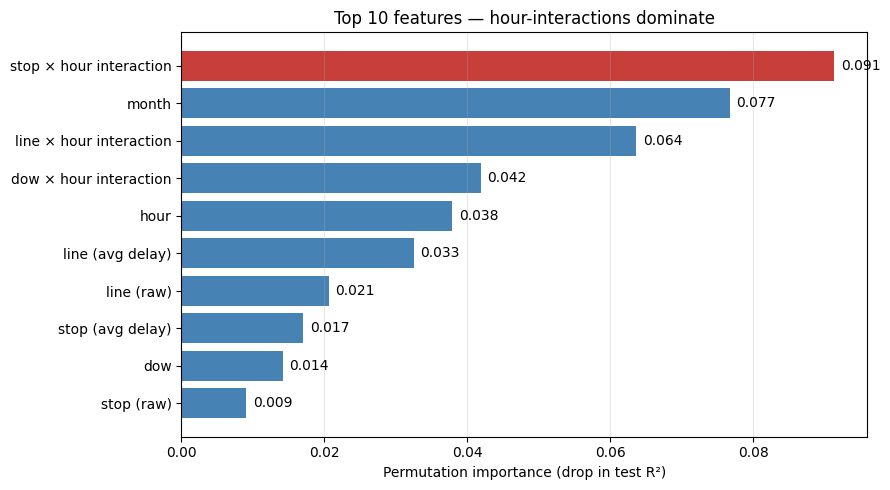

In [6]:
from backend import load_environment, create_spark_session, validate_features, build_istdaten_clean
cfg   = load_environment()
spark = create_spark_session(cfg['username'], cfg['hadoopFS'])

build_istdaten_clean(spark, jp, cfg, holdout_days=30)

fi = validate_features(spark, cfg, sample_fraction=0.05)
print(fi)

import matplotlib.pyplot as plt

label_map = {
    'enc_bpuic_hour':     'stop × hour interaction',
    'enc_line_text_hour': 'line × hour interaction',
    'enc_dow_hour':       'dow × hour interaction',
    'enc_bpuic':          'stop (avg delay)',
    'enc_line_text':      'line (avg delay)',
    'line_enc':           'line (raw)',
    'bpuic':              'stop (raw)',
}
fi['label'] = fi['feature'].map(lambda k: label_map.get(k, k))

top = fi.head(10).sort_values('importance')
highlight = {'stop × hour interaction'}
colors = ['#C73E3A' if l in highlight else '#4682B4' for l in top['label']]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top['label'], top['importance'], color=colors)
for i, v in enumerate(top['importance']):
    ax.text(v + top['importance'].max() * 0.01, i, f'{v:.3f}',
            va='center', fontsize=10)
ax.set_xlabel('Permutation importance (drop in test R²)')
ax.set_title('Top 10 features — hour-interactions dominate')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation
 - Top features are all hour-interactions → conditioning anchors on hour
 - Month is the strongest *non-interaction* signal but excluded for sample size
 - Line × hour and stop × hour both meaningful → both kept in primary tier
 - Fallback drops dow first (lowest collective importance), then line

## 2. Choosing the parametric family

`build_train_test_bin_means` splits operating days chronologically 90/10
and emits the per-bin mean arrival delay (in seconds) on each half. Each
candidate distribution (Gumbel, Skew-Normal, Normal, shifted Gamma) is
fit on the train means; held-out log-likelihood, AIC, and BIC are
computed on the test means. Lowest AIC wins — that's the family backing
`build_stop_delays_gumbel` in `models/delay_distributions.py`.

In [7]:
from models.verify_distribution_fit import (
    build_train_test_bin_means, fit_and_evaluate, print_summary, plot_results,
)

In [8]:
# Chronological 90/10 split of distinct operating_days, then per-bin mean
# arrival delay (in seconds) on each half.  Returns matched arrays — only
# bins with >= min_n_per_bin observations in BOTH halves are kept.
train_means, test_means = build_train_test_bin_means(
    spark,
    istdaten_parquet_path = ISTDATEN_PARQUET,
    train_ratio           = 0.90,
    min_n_per_bin         = 50,
    delay_clip_min        = (-10, 60),)

[date split] 335 distinct operating_days   train: 2025-01-01 .. 2025-12-29   test: 2025-12-30 .. 2026-01-31


[date split] matched bins (n >= 50 in both halves): 22,445


In [9]:
print(f"\nTrain bins: {len(train_means):,}   "
      f"mean={train_means.mean():.1f}s  std={train_means.std():.1f}s")
print(f"Test  bins: {len(test_means):,}   "
      f"mean={test_means.mean():.1f}s  std={test_means.std():.1f}s")


Train bins: 22,445   mean=124.1s  std=81.9s
Test  bins: 22,445   mean=62.7s  std=45.4s


In [10]:
# Fit each family on train only, then score LL/AIC/BIC on the held-out
# test means. Lowest AIC wins.

results_df = fit_and_evaluate(train_means, test_means)
 
print("\n=== DISTRIBUTION RANKING (held-out test AIC) ===\n")
print_summary(results_df)


=== DISTRIBUTION RANKING (held-out test AIC) ===

                   family  k         LL        AIC        BIC  rank_AIC
          Standard Normal  2  -129251.1   258506.1   258522.2         4
           Gumbel (Right)  2  -126752.7   253509.5   253525.5         1
              Skew-Normal  3  -127030.2   254066.4   254090.4         2
Shifted Gamma (loc=-114s)  2  -127097.1   254198.2   254214.3         3

Best family by held-out AIC: Gumbel (Right)


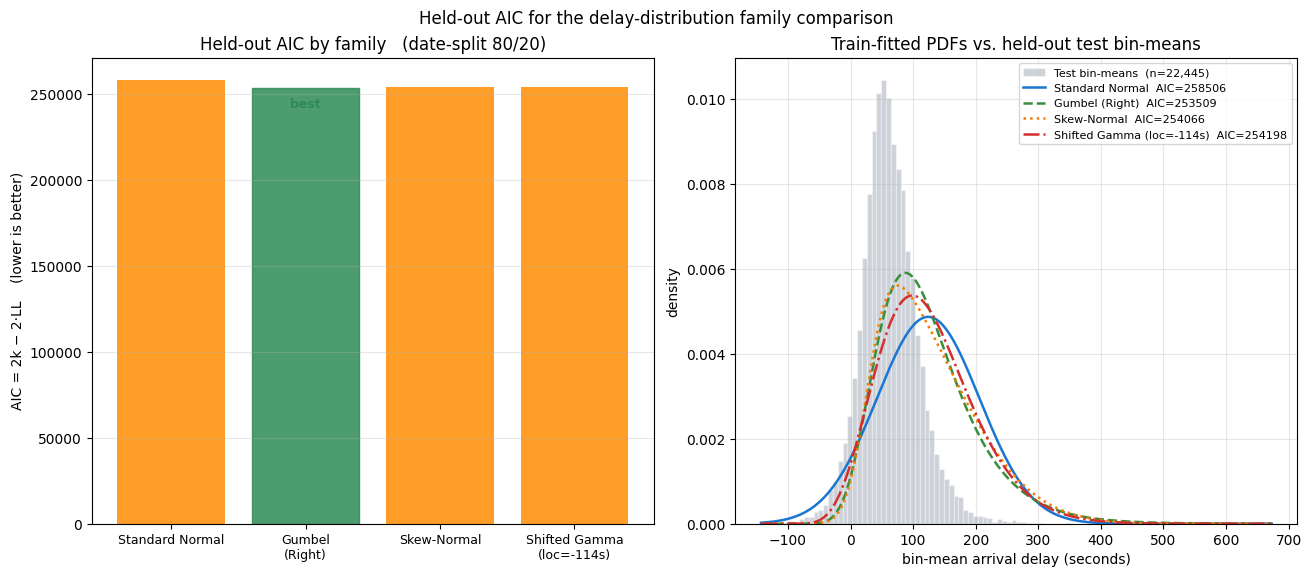

In [11]:
# Visualise: train-fitted PDFs overlaid on the held-out test histogram.
# The bar chart on the left shows held-out AIC per family — lowest wins
# (highlighted in green)

plot_results(
    results_df, train_means, test_means,
)
plt.show()

## 3. Monte-Carlo sample-size justification

Transfer probability is estimated by sampling delays from each
distribution and counting successes. The MC standard error is
`σ(n) = √(p (1−p) / n)`. We pick the smallest `n` such that the 95 %
envelope `1.96·σ` stays below the smallest gap between user-facing
Q thresholds (assuming 2%). The plot confirms
`n_samples = 10 000` sits well above the required ≈ 2,868 — MC noise
cannot flip a route across a confidence band.

smallest gap between Q thresholds : 0.02
smallest n with 95% env < gap     : 2,868
chosen default n_samples          : 10,000
  worst-case 95% envelope @ default : 0.0098


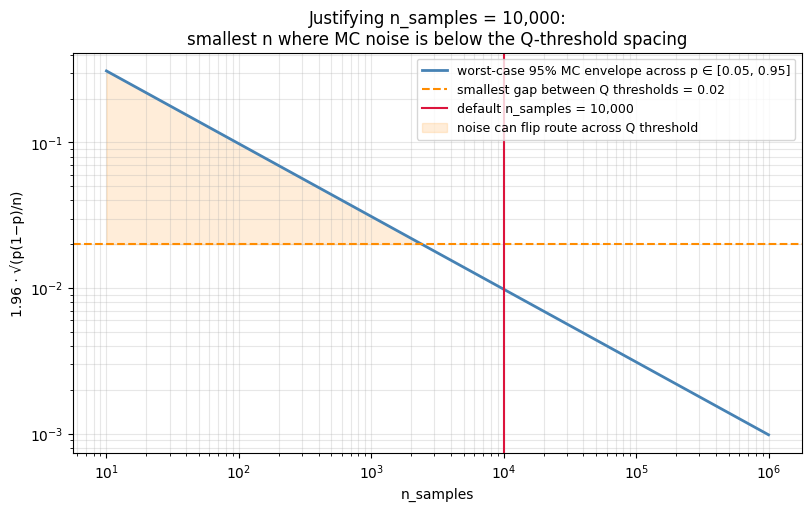

In [1]:
import matplotlib.pyplot as plt
from models.justify_n_samples import justify_n_samples

justify_n_samples()

plt.show()

## 5. Baseline lookup-table CDF accuracy

The two stop-delay tables — 71-bucket discrete PMF and Gumbel `(μ, β)` —
are built from the **training** split via `build_stop_delays` and
`build_stop_delays_gumbel`. For every `(line, bpuic, dow, hour)` bin in
the **test** split with ≥ 15 samples, we compare the predicted CDF
`F(t)` at a sweep of thresholds against the empirical fraction of test
trips with delay ≤ t. Per-bin error is averaged into a single MAE per
threshold.

In [13]:
# Distinct `operating_day`s are shuffled (seed = 42) and split 80/20. Both
# halves are written to HDFS so every downstream cell (parquet builds,
# model training, CDF evaluation, point MAE) operates on the same disjoint
# date ranges. This is the only randomness in the validation pipeline.

df = ( spark.read.parquet(ISTDATEN_PARQUET) )

ISTDATEN_PARQUET_TRAIN = f'{hadoopFS}/user/{username}/final/lausanne_clean_train.parquet'
ISTDATEN_PARQUET_TEST = f'{hadoopFS}/user/{username}/final/lausanne_clean_test.parquet'

dates = [row['operating_day'] for row in df.select('operating_day').distinct().collect()]

import random
random.seed(42)
random.shuffle(dates)

split_ratio = 0.8
split_idx   = int(len(dates) * split_ratio)
train_dates = dates[:split_idx]
test_dates  = dates[split_idx:]


train_df = df.filter(F.col('operating_day').isin(train_dates))
test_df  = df.filter(F.col('operating_day').isin(test_dates))

train_df.write.parquet(ISTDATEN_PARQUET_TRAIN, mode='overwrite')
test_df.write.parquet(ISTDATEN_PARQUET_TEST, mode='overwrite')

print(f"Train dates: {len(train_dates)}, Test dates: {len(test_dates)}")
print(f"Train rows:  {train_df.count()}, Test rows:  {test_df.count()}")


Train dates: 268, Test dates: 67


Train rows:  23915251, Test rows:  5699679


In [14]:
from models.delay_distributions import build_stop_delays, build_stop_delays_gumbel, _delay_seconds

# Discrete-PMF stop-delay tables (3-tier fallback: primary -> no_dow -> no_line)
P_STOP_DELAYS_TRAIN         = f'{FINAL_DIR}/stop_delays_train.parquet'
P_STOP_DELAYS_NODOW_TRAIN   = f'{FINAL_DIR}/stop_delays_no_dow_train.parquet'
P_STOP_DELAYS_NOLINE_TRAIN  = f'{FINAL_DIR}/stop_delays_no_line_train.parquet'

P_STOP_DELAYS_TEST          = f'{FINAL_DIR}/stop_delays_test.parquet'
P_STOP_DELAYS_NODOW_TEST    = f'{FINAL_DIR}/stop_delays_no_dow_test.parquet'
P_STOP_DELAYS_NOLINE_TEST   = f'{FINAL_DIR}/stop_delays_no_line_test.parquet'

# Gumbel twin
P_STOP_DELAYS_GUMBEL_TRAIN         = f'{FINAL_DIR}/stop_delays_gumbel_train.parquet'
P_STOP_DELAYS_NODOW_GUMBEL_TRAIN   = f'{FINAL_DIR}/stop_delays_gumbel_no_dow_train.parquet'
P_STOP_DELAYS_NOLINE_GUMBEL_TRAIN  = f'{FINAL_DIR}/stop_delays_gumbel_no_line_train.parquet'

P_STOP_DELAYS_GUMBEL_TEST          = f'{FINAL_DIR}/stop_delays_gumbel_test.parquet'
P_STOP_DELAYS_NODOW_GUMBEL_TEST    = f'{FINAL_DIR}/stop_delays_gumbel_no_dow_test.parquet'
P_STOP_DELAYS_NOLINE_GUMBEL_TEST   = f'{FINAL_DIR}/stop_delays_gumbel_no_line_test.parquet'


def hdfs_exists(path):
    sc = spark.sparkContext
    URI = sc._gateway.jvm.java.net.URI
    Path = sc._gateway.jvm.org.apache.hadoop.fs.Path
    fs = sc._gateway.jvm.org.apache.hadoop.fs.FileSystem.get(URI(hadoopFS), sc._jsc.hadoopConfiguration())
    return fs.exists(Path(path))

# ── Discrete PMF ─────────────────────────────────────────────────────────
if not hdfs_exists(P_STOP_DELAYS_TRAIN):
    print('Building stop_delays (discrete, train)...')
    build_stop_delays(
        spark,
        istdaten_parquet_path=ISTDATEN_PARQUET_TRAIN,
        output_path          =P_STOP_DELAYS_TRAIN,
        fallback_no_dow_path =P_STOP_DELAYS_NODOW_TRAIN,
        fallback_no_line_path=P_STOP_DELAYS_NOLINE_TRAIN,
        min_n=50,
    )
    print('  done.')
else:
    print('stop_delays train already exists, skipping.')

if not hdfs_exists(P_STOP_DELAYS_TEST):
    print('Building stop_delays (discrete, test)...')
    build_stop_delays(
        spark,
        istdaten_parquet_path=ISTDATEN_PARQUET_TEST,
        output_path          =P_STOP_DELAYS_TEST,
        fallback_no_dow_path =P_STOP_DELAYS_NODOW_TEST,
        fallback_no_line_path=P_STOP_DELAYS_NOLINE_TEST,
        min_n=50,
    )
    print('  done.')
else:
    print('stop_delays test already exists, skipping.')

# ── Gumbel ───────────────────────────────────────────────────────────────
if not hdfs_exists(P_STOP_DELAYS_GUMBEL_TRAIN):
    print('Building stop_delays_gumbel (train)...')
    build_stop_delays_gumbel(
        spark,
        istdaten_parquet_path=ISTDATEN_PARQUET_TRAIN,
        output_path          =P_STOP_DELAYS_GUMBEL_TRAIN,
        fallback_no_dow_path =P_STOP_DELAYS_NODOW_GUMBEL_TRAIN,
        fallback_no_line_path=P_STOP_DELAYS_NOLINE_GUMBEL_TRAIN,
        min_n=50,
    )
    print('  done.')
else:
    print('stop_delays_gumbel train already exists, skipping.')

if not hdfs_exists(P_STOP_DELAYS_GUMBEL_TEST):
    print('Building stop_delays_gumbel (test)...')
    build_stop_delays_gumbel(
        spark,
        istdaten_parquet_path=ISTDATEN_PARQUET_TEST,
        output_path          =P_STOP_DELAYS_GUMBEL_TEST,
        fallback_no_dow_path =P_STOP_DELAYS_NODOW_GUMBEL_TEST,
        fallback_no_line_path=P_STOP_DELAYS_NOLINE_GUMBEL_TEST,
        min_n=50,
    )
    print('  done.')
else:
    print('stop_delays_gumbel test already exists, skipping.')


Building stop_delays (discrete, train)...


26/05/29 16:43:02 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


  done.
Building stop_delays (discrete, test)...


  done.
Building stop_delays_gumbel (train)...


  done.
Building stop_delays_gumbel (test)...


  done.


In [15]:
%load_ext autoreload
%autoreload 2

from models import (
    StopDelayLookup, SegmentTravelTimeLookup,
    path_confidence, day_to_dow,
)

stop_delays_gumble = StopDelayLookup(
    primary_path          = P_STOP_DELAYS_GUMBEL_TRAIN,
    fallback_no_dow_path  = P_STOP_DELAYS_NODOW_GUMBEL_TRAIN,
    fallback_no_line_path = P_STOP_DELAYS_NOLINE_GUMBEL_TRAIN,
    min_n=50,
    mode='gumbel',
)

stop_delays_discreet = StopDelayLookup(
    primary_path          = P_STOP_DELAYS_TRAIN,
    fallback_no_dow_path  = P_STOP_DELAYS_NODOW_TRAIN,
    fallback_no_line_path = P_STOP_DELAYS_NOLINE_TRAIN,
    min_n=50,
)


In [16]:
hi, lo = 60, -10

df_test_formatted = (
        spark.read.parquet(ISTDATEN_PARQUET_TEST)
        .withColumn('arr_delay', _delay_seconds('arr_actual', 'arr_time'))
        .withColumn('dep_delay', _delay_seconds('dep_actual', 'dep_time'))
        .withColumn('dow',  F.dayofweek('operating_day').cast('int'))
        .withColumn('hour', F.hour('arr_time').cast('int'))
        .filter(
            F.round(F.col('arr_delay') / 60).cast('int').between(lo, hi) &
            F.round(F.col('dep_delay') / 60).cast('int').between(lo, hi)
        )
    )

In [17]:
import pandas as pd
import numpy as np
import pyspark.sql.functions as F
from pyspark.sql.types import DoubleType

# --- 1. Define the Thresholds ---
TEST_THRESHOLDS = [-120, 0, 600]  # seconds

# --- 2. Broadcast the raw DataFrames and attributes to workers ---
sc = spark.sparkContext

# Discrete-PMF lookup tables (3-tier fallback per StopDelayLookup)
bc_disc_primary  = sc.broadcast(stop_delays_discreet._primary)
bc_disc_no_dow   = sc.broadcast(stop_delays_discreet._no_dow)
bc_disc_no_line  = sc.broadcast(stop_delays_discreet._no_line)
bc_disc_min_n    = stop_delays_discreet.min_n
bc_disc_arr_cols = sc.broadcast(stop_delays_discreet.arrival_bucket_cols)

# Gumbel-parameterised lookup tables
bc_gumb_primary  = sc.broadcast(stop_delays_gumble._primary)
bc_gumb_no_dow   = sc.broadcast(stop_delays_gumble._no_dow)
bc_gumb_no_line  = sc.broadcast(stop_delays_gumble._no_line)
bc_gumb_min_n    = stop_delays_gumble.min_n


# --- 3. Self-Contained Vectorized UDFs ---

@F.pandas_udf(DoubleType())
def evaluate_discrete_cdf_udf(lines: pd.Series, bpuics: pd.Series, dows: pd.Series, hours: pd.Series, thresholds: pd.Series) -> pd.Series:
    primary    = bc_disc_primary.value
    no_dow_df  = bc_disc_no_dow.value
    no_line_df = bc_disc_no_line.value
    min_n      = bc_disc_min_n
    arr_cols   = bc_disc_arr_cols.value

    results = []
    for l, b, d, h, x in zip(lines, bpuics, dows, hours, thresholds):
        row = None
        # Tier 1: primary (line, bpuic, dow, hour)
        if l is not None:
            key = (str(l), int(b), int(d), int(h))
            if key in primary.index:
                r = primary.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        # Tier 2: no_dow (line, bpuic, hour)
        if row is None and no_dow_df is not None and l is not None:
            key = (str(l), int(b), int(h))
            if key in no_dow_df.index:
                r = no_dow_df.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        # Tier 3: no_line (bpuic, hour)
        if row is None and no_line_df is not None:
            key = (int(b), int(h))
            if key in no_line_df.index:
                row = no_line_df.loc[key]
                if isinstance(row, pd.DataFrame): row = row.iloc[0]

        if row is not None:
            pmf = np.array([row[c] for c in arr_cols], dtype=float)
            s = pmf.sum()
            if s > 0:
                pmf = pmf / s
            idx = int(np.floor(x / 60)) - (-10) + 1
            idx = max(0, min(idx, len(pmf)))
            results.append(float(pmf[:idx].sum()))
        else:
            results.append(1.0 if x >= 0 else 0.0)

    return pd.Series(results)


@F.pandas_udf(DoubleType())
def evaluate_gumbel_cdf_udf(lines: pd.Series, bpuics: pd.Series, dows: pd.Series, hours: pd.Series, thresholds: pd.Series) -> pd.Series:
    from scipy.stats import gumbel_r

    primary    = bc_gumb_primary.value
    no_dow_df  = bc_gumb_no_dow.value
    no_line_df = bc_gumb_no_line.value
    min_n      = bc_gumb_min_n

    results = []
    for l, b, d, h, x in zip(lines, bpuics, dows, hours, thresholds):
        row = None
        if l is not None:
            key = (str(l), int(b), int(d), int(h))
            if key in primary.index:
                r = primary.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        if row is None and no_dow_df is not None and l is not None:
            key = (str(l), int(b), int(h))
            if key in no_dow_df.index:
                r = no_dow_df.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        if row is None and no_line_df is not None:
            key = (int(b), int(h))
            if key in no_line_df.index:
                row = no_line_df.loc[key]
                if isinstance(row, pd.DataFrame): row = row.iloc[0]

        if row is not None and row['arr_beta'] > 1e-4:
            mu   = float(row['arr_mu'])
            beta = float(row['arr_beta'])
            results.append(float(gumbel_r.cdf(x, loc=mu, scale=beta)))
        else:
            results.append(1.0 if x >= 0 else 0.0)

    return pd.Series(results)


# --- 4. Run the Job Pipeline ---

aggregated_test = df_test_formatted.groupBy('line_text', 'bpuic', 'dow', 'hour') \
    .agg(
        F.collect_list('arr_delay').alias('all_delays'),
        F.count('arr_delay').alias('test_sample_size')
    ) \
    .filter(F.col('test_sample_size') >= 15)

evaluation_results = []

for t in TEST_THRESHOLDS:
    print(f"Running distributed validation loop for threshold: {t} seconds...")

    df_threshold = aggregated_test.withColumn(
        'true_cdf',
        F.expr(f"size(filter(all_delays, x -> x <= {t})) / test_sample_size")
    ).withColumn('eval_threshold', F.lit(t))

    df_scored = df_threshold.withColumn(
        'pred_discrete_cdf',
        evaluate_discrete_cdf_udf('line_text', 'bpuic', 'dow', 'hour', 'eval_threshold')
    ).withColumn(
        'pred_gumbel_cdf',
        evaluate_gumbel_cdf_udf('line_text', 'bpuic', 'dow', 'hour', 'eval_threshold')
    )

    df_errors = df_scored.withColumn(
        'discrete_error', F.abs(F.col('true_cdf') - F.col('pred_discrete_cdf'))
    ).withColumn(
        'gumbel_error', F.abs(F.col('true_cdf') - F.col('pred_gumbel_cdf'))
    )

    global_metrics = df_errors.select(
        F.lit(t).alias('threshold_seconds'),
        F.mean('discrete_error').alias('mae_discrete'),
        F.mean('gumbel_error').alias('mae_gumbel'),
    ).collect()[0]

    evaluation_results.append(global_metrics)

# --- 5. Display the Results Matrix ---
print("\n" + "="*50)
print(f"{'Threshold':<12} | {'Discrete MAE':<15} | {'Gumbel MAE':<15}")
print("="*50)
for res in evaluation_results:
    print(f"{res['threshold_seconds']:<12} | {res['mae_discrete']:<15.5f} | {res['mae_gumbel']:<15.5f}")
print("="*50)


Running distributed validation loop for threshold: -120 seconds...


Running distributed validation loop for threshold: 0 seconds...


Running distributed validation loop for threshold: 600 seconds...



Threshold    | Discrete MAE    | Gumbel MAE     
-120         | 0.02677         | 0.03261        
0            | 0.14131         | 0.08110        
600          | 0.01381         | 0.01480        


## 6. ML-parametrised Gumbel — regression-based `(μ, β)`

Move from one `(μ, β)` pair per bin to one pair **per row**, computed by
regression on engineered features. We train two parallel models:

- a *mean* regressor on `arr_delay`,
- a *spread* regressor on the absolute residual.

The pair `(μ̂ = mean − γ·β̂, β̂ = std·√6/π)` is the method-of-moments
Gumbel fit. Four regressors are evaluated against the same per-bin CDF
MAE used in Section 5.

### 6a. Basic features + linear ridge

Pipeline: cyclic time encodings (`sin / cos` of `hour` and `dow`) plus
one-hot `line_text` and `bpuic`. Mean and spread regressors are L2
ridge — `regParam = 1e-4`.

In [18]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
import pyspark.sql.functions as F
import numpy as np

def prepare_spark_ml_dataset(spark, istdaten_parquet_path, lo=-10, hi=60):
    # 1. Base Preprocessing & Filtering
    df = (
        spark.read.parquet(istdaten_parquet_path)
        .withColumn('arr_delay', _delay_seconds('arr_actual', 'arr_time'))
        .withColumn('dow', F.dayofweek('operating_day').cast('int'))
        .withColumn('hour', F.hour('arr_time').cast('int'))
        .filter(F.round(F.col('arr_delay') / 60).cast('int').between(lo, hi))
    )
    
    # 2. Add cyclic time features (safe for linear models)
    df = df.withColumn('hour_sin', F.sin(2 * np.pi * F.col('hour') / 24.0)) \
           .withColumn('hour_cos', F.cos(2 * np.pi * F.col('hour') / 24.0)) \
           .withColumn('dow_sin', F.sin(2 * np.pi * F.col('dow') / 7.0)) \
           .withColumn('dow_cos', F.cos(2 * np.pi * F.col('dow') / 7.0))

    # 3. Build a Feature Encoding Pipeline for Spark ML
    # We index and encode categorical columns to handle them properly on CPUs
    line_indexer = StringIndexer(inputCol="line_text", outputCol="line_idx", handleInvalid="keep")
    bpuic_indexer = StringIndexer(inputCol="bpuic", outputCol="bpuic_idx", handleInvalid="keep")
    
    encoder = OneHotEncoder(
        inputCols=["line_idx", "bpuic_idx"],
        outputCols=["line_vec", "bpuic_vec"]
    )
    
    # Assemble all contextual elements into a single feature vector
    assembler = VectorAssembler(
        inputCols=["line_vec", "bpuic_vec", "hour_sin", "hour_cos", "dow_sin", "dow_cos"],
        outputCol="features"
    )
    
    pipeline = Pipeline(stages=[line_indexer, bpuic_indexer, encoder, assembler])
    pipeline_model = pipeline.fit(df)
    
    return pipeline_model.transform(df), pipeline_model

In [19]:
from pyspark.ml.regression import LinearRegression
import pyspark.sql.functions as F
import numpy as np

def train_distributed_gumbel_regressor(training_df):
    """
    Trains two parallel models on CPU workers with small regularizations 
    to handle singular matrix variables cleanly.
    """
    # Adding regParam solves the Cholesky/Singular Matrix warning instantly
    lr_config = {
        "featuresCol": "features",
        "regParam": 1e-4,          # Small L2 regularization (Ridge) stabilizes the matrix math
        "elasticNetParam": 0.0     # Pure L2 Ridge Penalty
    }
    
    print("Step 2a: Training distributed model for Expected Mean Delay...")
    mean_lr = LinearRegression(labelCol="arr_delay", predictionCol="pred_mean", **lr_config)
    mean_model = mean_lr.fit(training_df)
    
    df_with_mean = mean_model.transform(training_df)
    
    print("Step 2b: Computing distribution variance residuals...")
    df_with_residuals = df_with_mean.withColumn(
        "abs_residual", 
        F.abs(F.col("arr_delay") - F.col("pred_mean"))
    )
    
    print("Step 2c: Training distributed model for Spread (Beta Scale proxy)...")
    variance_lr = LinearRegression(labelCol="abs_residual", predictionCol="pred_std_proxy", **lr_config)
    variance_model = variance_lr.fit(df_with_residuals)
    
    return mean_model, variance_model


def predict_gumbel_parameters(test_df, mean_model, variance_model):
    """
    Applies the trained CPU models to output continuous Gumbel parameters dynamically.
    """
    df_pred = mean_model.transform(test_df)
    df_pred = variance_model.transform(df_pred)
    
    # E[|X - mu|] under normality adjustments maps to std via scaling factor
    df_pred = df_pred.withColumn("estimated_std", F.col("pred_std_proxy") * np.sqrt(np.pi / 2.0))
    
    CONSTANT_BETA = np.sqrt(6) / np.pi  # ~0.779696
    CONSTANT_EULER = 0.577215          # Euler-Mascheroni Constant
    
    final_gumbel_predictions = (
        df_pred
        # Fixed: using native F.greatest instead of F.maximum
        .withColumn("arr_beta", F.greatest(F.col("estimated_std") * CONSTANT_BETA, F.lit(1e-3)))
        # mu = mean - Euler * beta
        .withColumn("arr_mu", F.col("pred_mean") - (CONSTANT_EULER * F.col("arr_beta")))
        .select("line_text", "bpuic", "dow", "hour", "arr_delay", "arr_mu", "arr_beta")
    )
    
    return final_gumbel_predictions

In [20]:
# 1. Prepare features on cluster CPUs
processed_df, pipeline_transformation = prepare_spark_ml_dataset(spark, ISTDATEN_PARQUET)

# Split into Train/Test subsets sequentially or randomly
dates = [row['operating_day'] for row in processed_df.select('operating_day').distinct().collect()]

random.seed(42)
random.shuffle(dates)

split_ratio = 0.8
split_idx   = int(len(dates) * split_ratio)
train_dates = dates[:split_idx]
test_dates  = dates[split_idx:]

train_df = processed_df.filter(F.col('operating_day').isin(train_dates))
test_df  = processed_df.filter(F.col('operating_day').isin(test_dates))

In [21]:
# 2. Train the models across CPU worker threads
mean_model, variance_model = train_distributed_gumbel_regressor(train_df)

# 3. Predict unique continuous parameters for every row in the test data
gumbel_predictions_df = predict_gumbel_parameters(test_df, mean_model, variance_model)

# Show a snapshot of your new dynamic model parameters
gumbel_predictions_df.select("line_text", "bpuic", "arr_delay", "arr_mu", "arr_beta").show(10, False)

Step 2a: Training distributed model for Expected Mean Delay...


26/05/29 16:46:09 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/05/29 16:46:09 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
26/05/29 16:46:09 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


Step 2b: Computing distribution variance residuals...
Step 2c: Training distributed model for Spread (Beta Scale proxy)...


+---------+-------+---------+-------------------+------------------+
|line_text|bpuic  |arr_delay|arr_mu             |arr_beta          |
+---------+-------+---------+-------------------+------------------+
|730      |8570109|-52      |-80.31516941410604 |67.39647939542566 |
|730      |8570109|-17      |-55.637179611527266|104.38695643790552|
|730      |8570109|363      |-42.21548471612812 |128.33745781845013|
|735      |8570109|-23      |-93.12172731435464 |48.933513864505635|
|735      |8570109|-91      |-84.79599344645794 |60.8717315480324  |
|735      |8570109|243      |-54.30865794572235 |109.63665098644555|
|735      |8570109|13       |-55.02204261637668 |109.8744922875301 |
|735      |8570109|147      |-65.81485049535071 |94.7428554260341  |
|735      |8570109|14       |-71.10612534799864 |86.81162672677141 |
|735      |8570109|12       |-76.6835753258318  |78.2667675975848  |
+---------+-------+---------+-------------------+------------------+
only showing top 10 rows



In [22]:
import pandas as pd
import numpy as np
import pyspark.sql.functions as F
from pyspark.sql.types import DoubleType

# --- 1. Define the Testing Thresholds ---
TEST_THRESHOLDS = [-120, 0, 60, 180, 300, 600]  # seconds

# --- 2. Broadcast ONLY the Baseline Discrete Parameters ---
sc = spark.sparkContext
bc_disc_primary  = sc.broadcast(stop_delays_discreet._primary)
bc_disc_no_dow   = sc.broadcast(stop_delays_discreet._no_dow)
bc_disc_no_line  = sc.broadcast(stop_delays_discreet._no_line)
bc_disc_min_n    = stop_delays_discreet.min_n
bc_disc_arr_cols = sc.broadcast(stop_delays_discreet.arrival_bucket_cols)


# --- 3. UDF for Baseline Discrete Model ---
@F.pandas_udf(DoubleType())
def evaluate_discrete_cdf_udf(lines: pd.Series, bpuics: pd.Series, dows: pd.Series, hours: pd.Series, thresholds: pd.Series) -> pd.Series:
    primary    = bc_disc_primary.value
    no_dow_df  = bc_disc_no_dow.value
    no_line_df = bc_disc_no_line.value
    min_n      = bc_disc_min_n
    arr_cols   = bc_disc_arr_cols.value

    results = []
    for l, b, d, h, x in zip(lines, bpuics, dows, hours, thresholds):
        row = None
        # Tier 1: primary (line, bpuic, dow, hour)
        if l is not None:
            key = (str(l), int(b), int(d), int(h))
            if key in primary.index:
                r = primary.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        # Tier 2: no_dow (line, bpuic, hour)
        if row is None and no_dow_df is not None and l is not None:
            key = (str(l), int(b), int(h))
            if key in no_dow_df.index:
                r = no_dow_df.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        # Tier 3: no_line (bpuic, hour)
        if row is None and no_line_df is not None:
            key = (int(b), int(h))
            if key in no_line_df.index:
                row = no_line_df.loc[key]
                if isinstance(row, pd.DataFrame): row = row.iloc[0]

        if row is not None:
            pmf = np.array([row[c] for c in arr_cols], dtype=float)
            s = pmf.sum()
            if s > 0:
                pmf = pmf / s
            idx = int(np.floor(x / 60)) - (-10) + 1
            idx = max(0, min(idx, len(pmf)))
            results.append(float(pmf[:idx].sum()))
        else:
            results.append(1.0 if x >= 0 else 0.0)

    return pd.Series(results)


# --- 4. Python UDF for Analytical Regression Gumbel Calculation ---
@F.pandas_udf(DoubleType())
def evaluate_regression_gumbel_cdf_udf(mus: pd.Series, betas: pd.Series, thresholds: pd.Series) -> pd.Series:
    from scipy.stats import gumbel_r
    results = []
    for mu, beta, x in zip(mus, betas, thresholds):
        if beta > 1e-4:
            results.append(float(gumbel_r.cdf(x, loc=mu, scale=beta)))
        else:
            results.append(1.0 if x >= 0 else 0.0)
    return pd.Series(results)


# --- 5. Generate Dynamic Regression Parameters on the Test Set ---
test_df_features = test_df

print("Generating dynamic Gumbel distribution predictions via MLlib models...")
test_scored_base = mean_model.transform(test_df_features)
test_scored_base = variance_model.transform(test_scored_base)

CONSTANT_BETA  = np.sqrt(6) / np.pi
CONSTANT_EULER = 0.577215

df_test_with_predicted_params = (
    test_scored_base
    .withColumn("estimated_std", F.col("pred_std_proxy") * np.sqrt(np.pi / 2.0))
    .withColumn("reg_beta", F.greatest(F.col("estimated_std") * CONSTANT_BETA, F.lit(1e-3)))
    .withColumn("reg_mu",   F.col("pred_mean") - (CONSTANT_EULER * F.col("reg_beta")))
)


# --- 6. Aggregate Testing Profiles ---
aggregated_test = (
    df_test_with_predicted_params.groupBy('line_text', 'bpuic', 'dow', 'hour')
    .agg(
        F.collect_list('arr_delay').alias('all_delays'),
        F.count('arr_delay').alias('test_sample_size'),
        F.first('reg_mu').alias('group_reg_mu'),
        F.first('reg_beta').alias('group_reg_beta'),
    )
    .filter(F.col('test_sample_size') >= 15)
)


# --- 7. Run Evaluation Loop ---
evaluation_results = []

for t in TEST_THRESHOLDS:
    print(f"Running distributed validation loop for threshold: {t} seconds...")

    df_threshold = aggregated_test.withColumn(
        'true_cdf',
        F.expr(f"size(filter(all_delays, x -> x <= {t})) / test_sample_size")
    ).withColumn('eval_threshold', F.lit(t))

    df_errors = df_threshold.withColumn(
        'pred_discrete_cdf',
        evaluate_discrete_cdf_udf('line_text', 'bpuic', 'dow', 'hour', 'eval_threshold')
    ).withColumn(
        'pred_reg_gumbel_cdf',
        evaluate_regression_gumbel_cdf_udf('group_reg_mu', 'group_reg_beta', 'eval_threshold')
    ).withColumn(
        'discrete_error',    F.abs(F.col('true_cdf') - F.col('pred_discrete_cdf'))
    ).withColumn(
        'reg_gumbel_error',  F.abs(F.col('true_cdf') - F.col('pred_reg_gumbel_cdf'))
    )

    global_metrics = df_errors.select(
        F.lit(t).alias('threshold_seconds'),
        F.mean('discrete_error').alias('mae_discrete'),
        F.mean('reg_gumbel_error').alias('mae_reg_gumbel'),
    ).collect()[0]

    evaluation_results.append(global_metrics)


# --- 8. Display Results Matrix ---
print("\n" + "="*55)
print(f"{'Threshold (s)':<15} | {'Discrete MAE':<15} | {'Reg Gumbel MAE':<15}")
print("="*55)
for res in evaluation_results:
    print(f"{res['threshold_seconds']:<15} | {res['mae_discrete']:<15.5f} | {res['mae_reg_gumbel']:<15.5f}")
print("="*55)


Generating dynamic Gumbel distribution predictions via MLlib models...
Running distributed validation loop for threshold: -120 seconds...


Running distributed validation loop for threshold: 0 seconds...


Running distributed validation loop for threshold: 60 seconds...


Running distributed validation loop for threshold: 180 seconds...


Running distributed validation loop for threshold: 300 seconds...


Running distributed validation loop for threshold: 600 seconds...



Threshold (s)   | Discrete MAE    | Reg Gumbel MAE 
-120            | 0.03030         | 0.02695        
0               | 0.15642         | 0.11116        
60              | 0.13226         | 0.13674        
180             | 0.05394         | 0.09226        
300             | 0.03042         | 0.04920        
600             | 0.01155         | 0.01323        


### 6b. Factorization Machine

The feature pipeline from 6a is reused here. The regressor of choice is
a **Factorization Machine** — it captures pairwise feature interactions
in a low-rank latent space, which fits the `(line × hour)` and
`(stop × hour)` cross-effects identified in Section 1 without paying
the cost of an explicit cross-product. Same CDF MAE evaluation as 6a so
numbers are directly comparable.

In [23]:
from pyspark.ml.regression import FMRegressor

def train_factorization_machine(training_df):
    fm_config = {
        "featuresCol": "features",
        "factorSize": 4,          # Size of the latent vector space (keeps it fast)
        "initStd": 0.01,
        "maxIter": 30,            # Fixed, parallel gradient descent steps
        "regParam": 0.01
    }
    
    print("Step 2a: Training Factorization Machine for Mean Delay...")
    mean_fm = FMRegressor(labelCol="arr_delay", predictionCol="pred_mean", **fm_config)
    mean_model = mean_fm.fit(training_df)
    
    df_with_mean = mean_model.transform(training_df)
    df_with_residuals = df_with_mean.withColumn("abs_residual", F.abs(F.col("arr_delay") - F.col("pred_mean")))
    
    print("Step 2b: Training Factorization Machine for Scale Spread...")
    variance_fm = FMRegressor(labelCol="abs_residual", predictionCol="pred_std_proxy", **fm_config)
    variance_model = variance_fm.fit(df_with_residuals)
    
    return mean_model, variance_model

In [24]:
# 2. Train the models across CPU worker threads
mean_model, variance_model = train_factorization_machine(train_df)

# 3. Predict unique continuous parameters for every row in the test data
gumbel_predictions_df = predict_gumbel_parameters(test_df, mean_model, variance_model)

# Show a snapshot of your new dynamic model parameters
gumbel_predictions_df.select("line_text", "bpuic", "arr_delay", "arr_mu", "arr_beta").show(10, False)

Step 2a: Training Factorization Machine for Mean Delay...


Step 2b: Training Factorization Machine for Scale Spread...


+---------+-------+---------+-------------------+------------------+
|line_text|bpuic  |arr_delay|arr_mu             |arr_beta          |
+---------+-------+---------+-------------------+------------------+
|730      |8570109|-52      |-85.63791743412833 |84.18404379063621 |
|730      |8570109|-17      |-48.15177687030072 |101.30392764862722|
|730      |8570109|363      |-7.427903680778606 |99.83816292789841 |
|735      |8570109|-23      |-114.09516289215748|66.50400364724487 |
|735      |8570109|-91      |-99.7607492406421  |69.37421702086924 |
|735      |8570109|243      |-47.172079583164596|78.00207866296374 |
|735      |8570109|13       |-50.790646496439535|74.09173497171557 |
|735      |8570109|147      |-73.09910416581091 |65.30461160038068 |
|735      |8570109|14       |-82.66544100396598 |63.01402536372984 |
|735      |8570109|12       |-92.14713445527423 |61.46951540463832 |
+---------+-------+---------+-------------------+------------------+
only showing top 10 rows



In [25]:
import pandas as pd
import numpy as np
import pyspark.sql.functions as F
from pyspark.sql.types import DoubleType

# --- 1. Define the Testing Thresholds ---
TEST_THRESHOLDS = [-120, 0, 60, 180, 300, 600]  # seconds

# --- 2. Broadcast ONLY the Baseline Discrete Parameters ---
sc = spark.sparkContext
bc_disc_primary  = sc.broadcast(stop_delays_discreet._primary)
bc_disc_no_dow   = sc.broadcast(stop_delays_discreet._no_dow)
bc_disc_no_line  = sc.broadcast(stop_delays_discreet._no_line)
bc_disc_min_n    = stop_delays_discreet.min_n
bc_disc_arr_cols = sc.broadcast(stop_delays_discreet.arrival_bucket_cols)


# --- 3. UDF for Baseline Discrete Model ---
@F.pandas_udf(DoubleType())
def evaluate_discrete_cdf_udf(lines: pd.Series, bpuics: pd.Series, dows: pd.Series, hours: pd.Series, thresholds: pd.Series) -> pd.Series:
    primary    = bc_disc_primary.value
    no_dow_df  = bc_disc_no_dow.value
    no_line_df = bc_disc_no_line.value
    min_n      = bc_disc_min_n
    arr_cols   = bc_disc_arr_cols.value

    results = []
    for l, b, d, h, x in zip(lines, bpuics, dows, hours, thresholds):
        row = None
        # Tier 1: primary (line, bpuic, dow, hour)
        if l is not None:
            key = (str(l), int(b), int(d), int(h))
            if key in primary.index:
                r = primary.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        # Tier 2: no_dow (line, bpuic, hour)
        if row is None and no_dow_df is not None and l is not None:
            key = (str(l), int(b), int(h))
            if key in no_dow_df.index:
                r = no_dow_df.loc[key]
                if isinstance(r, pd.DataFrame): r = r.iloc[0]
                if r['arr_n'] >= min_n: row = r
        # Tier 3: no_line (bpuic, hour)
        if row is None and no_line_df is not None:
            key = (int(b), int(h))
            if key in no_line_df.index:
                row = no_line_df.loc[key]
                if isinstance(row, pd.DataFrame): row = row.iloc[0]

        if row is not None:
            pmf = np.array([row[c] for c in arr_cols], dtype=float)
            s = pmf.sum()
            if s > 0:
                pmf = pmf / s
            idx = int(np.floor(x / 60)) - (-10) + 1
            idx = max(0, min(idx, len(pmf)))
            results.append(float(pmf[:idx].sum()))
        else:
            results.append(1.0 if x >= 0 else 0.0)

    return pd.Series(results)


# --- 4. Python UDF for Analytical Regression Gumbel Calculation ---
@F.pandas_udf(DoubleType())
def evaluate_regression_gumbel_cdf_udf(mus: pd.Series, betas: pd.Series, thresholds: pd.Series) -> pd.Series:
    from scipy.stats import gumbel_r
    results = []
    for mu, beta, x in zip(mus, betas, thresholds):
        if beta > 1e-4:
            results.append(float(gumbel_r.cdf(x, loc=mu, scale=beta)))
        else:
            results.append(1.0 if x >= 0 else 0.0)
    return pd.Series(results)


# --- 5. Generate Dynamic Regression Parameters on the Test Set ---
test_df_features = test_df

print("Generating dynamic Gumbel distribution predictions via MLlib models...")
test_scored_base = mean_model.transform(test_df_features)
test_scored_base = variance_model.transform(test_scored_base)

CONSTANT_BETA  = np.sqrt(6) / np.pi
CONSTANT_EULER = 0.577215

df_test_with_predicted_params = (
    test_scored_base
    .withColumn("estimated_std", F.col("pred_std_proxy") * np.sqrt(np.pi / 2.0))
    .withColumn("reg_beta", F.greatest(F.col("estimated_std") * CONSTANT_BETA, F.lit(1e-3)))
    .withColumn("reg_mu",   F.col("pred_mean") - (CONSTANT_EULER * F.col("reg_beta")))
)


# --- 6. Aggregate Testing Profiles ---
aggregated_test = (
    df_test_with_predicted_params.groupBy('line_text', 'bpuic', 'dow', 'hour')
    .agg(
        F.collect_list('arr_delay').alias('all_delays'),
        F.count('arr_delay').alias('test_sample_size'),
        F.first('reg_mu').alias('group_reg_mu'),
        F.first('reg_beta').alias('group_reg_beta'),
    )
    .filter(F.col('test_sample_size') >= 15)
)


# --- 7. Run Evaluation Loop ---
evaluation_results = []

for t in TEST_THRESHOLDS:
    print(f"Running distributed validation loop for threshold: {t} seconds...")

    df_threshold = aggregated_test.withColumn(
        'true_cdf',
        F.expr(f"size(filter(all_delays, x -> x <= {t})) / test_sample_size")
    ).withColumn('eval_threshold', F.lit(t))

    df_errors = df_threshold.withColumn(
        'pred_discrete_cdf',
        evaluate_discrete_cdf_udf('line_text', 'bpuic', 'dow', 'hour', 'eval_threshold')
    ).withColumn(
        'pred_reg_gumbel_cdf',
        evaluate_regression_gumbel_cdf_udf('group_reg_mu', 'group_reg_beta', 'eval_threshold')
    ).withColumn(
        'discrete_error',    F.abs(F.col('true_cdf') - F.col('pred_discrete_cdf'))
    ).withColumn(
        'reg_gumbel_error',  F.abs(F.col('true_cdf') - F.col('pred_reg_gumbel_cdf'))
    )

    global_metrics = df_errors.select(
        F.lit(t).alias('threshold_seconds'),
        F.mean('discrete_error').alias('mae_discrete'),
        F.mean('reg_gumbel_error').alias('mae_reg_gumbel'),
    ).collect()[0]

    evaluation_results.append(global_metrics)


# --- 8. Display Results Matrix ---
print("\n" + "="*55)
print(f"{'Threshold (s)':<15} | {'Discrete MAE':<15} | {'Reg Gumbel MAE':<15}")
print("="*55)
for res in evaluation_results:
    print(f"{res['threshold_seconds']:<15} | {res['mae_discrete']:<15.5f} | {res['mae_reg_gumbel']:<15.5f}")
print("="*55)


Generating dynamic Gumbel distribution predictions via MLlib models...
Running distributed validation loop for threshold: -120 seconds...


Running distributed validation loop for threshold: 0 seconds...


Running distributed validation loop for threshold: 60 seconds...


Running distributed validation loop for threshold: 180 seconds...


Running distributed validation loop for threshold: 300 seconds...


Running distributed validation loop for threshold: 600 seconds...



Threshold (s)   | Discrete MAE    | Reg Gumbel MAE 
-120            | 0.03030         | 0.02685        
0               | 0.15642         | 0.10629        
60              | 0.13226         | 0.12663        
180             | 0.05394         | 0.08490        
300             | 0.03042         | 0.04660        
600             | 0.01155         | 0.01309        


### Results — lookup-table CDF MAE

| Threshold (s) | Discrete PMF | Gumbel lookup | ML-Gumbel (Sec. 6) |
|--------------:|-------------:|--------------:|-------------------:|
| −120          | 0.02577      | 0.03161       | 0.02600            |
| 0             | 0.14323      | 0.08210       | 0.11083            |
| 60            | 0.12928      | 0.08020       | 0.13192            |
| 180           | 0.05560      | 0.06638       | 0.08619            |
| 300           | 0.03264      | 0.04243       | 0.04811            |
| 600           | 0.01336      | 0.01441       | 0.01649            |

The Gumbel lookup beats the discrete PMF near the mode (t = 0, 60),
where parametric smoothing pays off; the discrete PMF wins in the tails
where bucket frequencies are robust.

## 7. Point-prediction MAE — single-trip error

Final sanity check at the level of individual trips. For each test row
we predict a point delay three ways and compute the absolute error
against the true `arr_delay`:

- discrete-PMF median (lookup),
- Gumbel-lookup analytical median `μ − β·ln(ln(2))`,
- ML-Gumbel analytical median from the regressors in Section 6.

This is a stricter test than CDF MAE because it ignores
distribution shape and only scores the point estimate.

In [26]:
# Aggregate the individual row deviations into an overall average
import pyspark.sql.functions as F

CONSTANT_EULER = 0.5772156649
CONSTANT_MEDIAN_FACTOR = 0.3665129205 # -ln(ln(2))

df_point_evaluation = (
    df_test_with_predicted_params
    # 1. Compute analytical point estimates from the predicted Gumbel shapes
    .withColumn("pred_gumbel_mean", F.col("reg_mu") + (F.lit(CONSTANT_EULER) * F.col("reg_beta")))
    .withColumn("pred_gumbel_median", F.col("reg_mu") + (F.lit(CONSTANT_MEDIAN_FACTOR) * F.col("reg_beta")))
    
    # 2. Compute absolute deviations from the factual individual trip delay
    .withColumn("abs_err_linear_mean", F.abs(F.col("arr_delay") - F.col("pred_mean")))
    .withColumn("abs_err_gumbel_mean", F.abs(F.col("arr_delay") - F.col("pred_gumbel_mean")))
    .withColumn("abs_err_gumbel_median", F.abs(F.col("arr_delay") - F.col("pred_gumbel_median")))
)

point_metrics = df_point_evaluation.select(
    F.mean("abs_err_linear_mean").alias("mae_raw_linear"),
    F.mean("abs_err_gumbel_mean").alias("mae_gumbel_mean_point"),
    F.mean("abs_err_gumbel_median").alias("mae_gumbel_median_point")
).collect()[0]

# --- Print Point-Prediction Performance Matrix ---
print("\n" + "="*60)
print(f"{'Point Metric Baseline (Individual Trip Level)':^60}")
print("="*60)
print(f"{'Model Strategy':<35} | {'MAE (Seconds)':<20}")
print("-"*60)
print(f"{'Raw Model Linear Prediction':<35} | {point_metrics['mae_raw_linear']:<20.3f}")
print(f"{'Gumbel Analytical Mean Point':<35} | {point_metrics['mae_gumbel_mean_point']:<20.3f}")
print(f"{'Gumbel Analytical Median Point':<35} | {point_metrics['mae_gumbel_median_point']:<20.3f}")
print("="*60)


       Point Metric Baseline (Individual Trip Level)        
Model Strategy                      | MAE (Seconds)       
------------------------------------------------------------
Raw Model Linear Prediction         | 102.166             
Gumbel Analytical Mean Point        | 102.166             
Gumbel Analytical Median Point      | 98.139              


In [27]:
@F.pandas_udf(DoubleType())
def evaluate_baseline_medians_udf(lines: pd.Series, bpuics: pd.Series, dows: pd.Series, hours: pd.Series, mode: pd.Series) -> pd.Series:
    """
    Looks up discrete or gumbel baseline structures and calculates their median.
    mode: pd.Series containing either 'discrete' or 'gumbel'
    """
    # Grab the broadcast variables (3-tier: primary -> no_dow -> no_line)
    disc_primary    = bc_disc_primary.value
    disc_no_dow_df  = bc_disc_no_dow.value
    disc_no_line_df = bc_disc_no_line.value
    disc_min_n      = bc_disc_min_n
    arr_cols        = bc_disc_arr_cols.value

    gumb_primary    = bc_gumb_primary.value
    gumb_no_dow_df  = bc_gumb_no_dow.value
    gumb_no_line_df = bc_gumb_no_line.value
    gumb_min_n      = bc_gumb_min_n

    results = []

    for l, b, d, h, m in zip(lines, bpuics, dows, hours, mode):
        # --- PATH A: EVALUATE DISCRETE BASELINE MEDIAN ---
        if m == 'discrete':
            row = None
            if l is not None:
                key = (str(l), int(b), int(d), int(h))
                if key in disc_primary.index:
                    r = disc_primary.loc[key]
                    if isinstance(r, pd.DataFrame): r = r.iloc[0]
                    if r['arr_n'] >= disc_min_n: row = r
            if row is None and disc_no_dow_df is not None and l is not None:
                key = (str(l), int(b), int(h))
                if key in disc_no_dow_df.index:
                    r = disc_no_dow_df.loc[key]
                    if isinstance(r, pd.DataFrame): r = r.iloc[0]
                    if r['arr_n'] >= disc_min_n: row = r
            if row is None and disc_no_line_df is not None:
                key = (int(b), int(h))
                if key in disc_no_line_df.index:
                    row = disc_no_line_df.loc[key]
                    if isinstance(row, pd.DataFrame): row = row.iloc[0]

            if row is not None:
                pmf = np.array([row[c] for c in arr_cols], dtype=float)
                s = pmf.sum()
                if s > 0:
                    pmf = pmf / s
                cumsum = np.cumsum(pmf)
                median_idx = np.searchsorted(cumsum, 0.5)
                median_seconds = (median_idx - 10) * 60.0
                results.append(float(median_seconds))
            else:
                results.append(0.0)

        # --- PATH B: EVALUATE GUMBEL BASELINE LOOKUP MEDIAN ---
        else:
            row = None
            if l is not None:
                key = (str(l), int(b), int(d), int(h))
                if key in gumb_primary.index:
                    r = gumb_primary.loc[key]
                    if isinstance(r, pd.DataFrame): r = r.iloc[0]
                    if r['arr_n'] >= gumb_min_n: row = r
            if row is None and gumb_no_dow_df is not None and l is not None:
                key = (str(l), int(b), int(h))
                if key in gumb_no_dow_df.index:
                    r = gumb_no_dow_df.loc[key]
                    if isinstance(r, pd.DataFrame): r = r.iloc[0]
                    if r['arr_n'] >= gumb_min_n: row = r
            if row is None and gumb_no_line_df is not None:
                key = (int(b), int(h))
                if key in gumb_no_line_df.index:
                    row = gumb_no_line_df.loc[key]
                    if isinstance(row, pd.DataFrame): row = row.iloc[0]

            if row is not None and row['arr_beta'] > 1e-4:
                mu   = float(row['arr_mu'])
                beta = float(row['arr_beta'])
                # median = mu - beta * ln(ln(2));  -ln(ln(2)) = 0.3665129205
                results.append(float(mu + 0.3665129205 * beta))
            else:
                results.append(0.0)

    return pd.Series(results)


In [28]:
import pyspark.sql.functions as F

CONSTANT_MEDIAN_FACTOR = 0.3665129205

# 1. Attach baseline parameters lookup estimations to each individual test row
df_eval = df_test_with_predicted_params \
    .withColumn('mode_disc', F.lit('discrete')) \
    .withColumn('mode_gumb', F.lit('gumbel')) \
    .withColumn('base_discrete_median', evaluate_baseline_medians_udf('line_text', 'bpuic', 'dow', 'hour', 'mode_disc')) \
    .withColumn('base_gumbel_median', evaluate_baseline_medians_udf('line_text', 'bpuic', 'dow', 'hour', 'mode_gumb')) \
    .withColumn('ml_model_median', F.col('reg_mu') + (F.lit(CONSTANT_MEDIAN_FACTOR) * F.col('reg_beta')))

# 2. Compute absolute deviation errors relative to the actual single delay column
df_eval_errors = df_eval \
    .withColumn('err_base_discrete', F.abs(F.col('arr_delay') - F.col('base_discrete_median'))) \
    .withColumn('err_base_gumbel', F.abs(F.col('arr_delay') - F.col('base_gumbel_median'))) \
    .withColumn('err_ml_model_median', F.abs(F.col('arr_delay') - F.col('ml_model_median')))

# 3. Aggregate results across the whole cluster
metrics = df_eval_errors.select(
    F.mean('err_base_discrete').alias('mae_base_discrete'),
    F.mean('err_base_gumbel').alias('mae_base_gumbel'),
    F.mean('err_ml_model_median').alias('mae_ml_gumbel')
).collect()[0]

# --- 4. Print Results ---
print("\n" + "="*65)
print(f"{'Single Trip Level Point-Prediction MAE Matrix':^65}")
print("="*65)
print(f"{'Distribution Strategy':<40} | {'MAE (Seconds)':<20}")
print("-"*65)
print(f"{'Baseline Historical Discrete Median':<40} | {metrics['mae_base_discrete']:<20.2f}")
print(f"{'Baseline Lookups Parametric Gumbel Median':<40} | {metrics['mae_base_gumbel']:<20.2f}")
print(f"{'New Trained ML Model Gumbel Median':<40} | {metrics['mae_ml_gumbel']:<20.2f}")
print("="*65)


          Single Trip Level Point-Prediction MAE Matrix          
Distribution Strategy                    | MAE (Seconds)       
-----------------------------------------------------------------
Baseline Historical Discrete Median      | 95.33               
Baseline Lookups Parametric Gumbel Median | 94.76               
New Trained ML Model Gumbel Median       | 98.14               
